# Solve Inverse Problems

There are a multitude of inverse solvers to choose from, each with its own advantages and limitations. Use this notebook to explore different solvers and visually compare their solutions.

Under the Bayesian framework, the inverse problem for distributed source spaces can be formulated as:$$\mathbf s^* = \text{argmin}_{\mathbf{s}} \lVert \mathbf C (\mathbf {Ls}-\mathbf y) \rVert_2^2 + \lambda \lVert \mathbf D \mathbf s \rVert_d^d$$

where:
- $\mathbf s^* \in \mathbb{R}^{n \times t}$ are the reconstructed dipole strengths
- $\mathbf y \in \mathbb{R}^{m \times t}$ is the measured data (sensor observations)
- $\mathbf L \in \mathbb{R}^{m\times n}$ is the lead field matrix
- $\lambda \in \mathbb{R}$ is the regularization parameter
- $\mathbf C \in \mathbb{R}^{m\times m}$ represents the noise weighting or noise interaction assumptions
- $\mathbf D \in \mathbb{R}^{n\times n}$ represents the source interaction or source weighting assumptions


## 📦 Imports

In [6]:
import mindmap as mm
import mne
import numpy as np

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: Preprocessed EEG $\rightarrow \mathbf y$
- `fwd`: Forward operator $\rightarrow \mathbf L$
- `ncov`: Noise covariance matrix $\rightarrow \mathbf C$
- `cst`: Connectome spectrum transform $\rightarrow \mathbf U$ (see CSET and wCSET)
- `gt`: Ground Truth (optional)
- `resec`: Resection area (optional)

In [11]:
# ------------- Parameters ---------------
fconfig = "../../data/config.yml"
subject = "intra-12"
task    = "spk"
run     = None
# ----------------------------------------

reader = mm.io.TutoReader(fconfig)
data   = reader(subject, "fwd", "ave", "gt-1", "ncov", "eig", task=task, run=run)

DATA SUMMARY
Dataset: tuto
Subject: intra-12
Task: spk
Run: None
Retrieved objects:
- ave
- eig
- fwd
- ncov
Missing objects:
- gt-1


📊 **Check EEG signal**

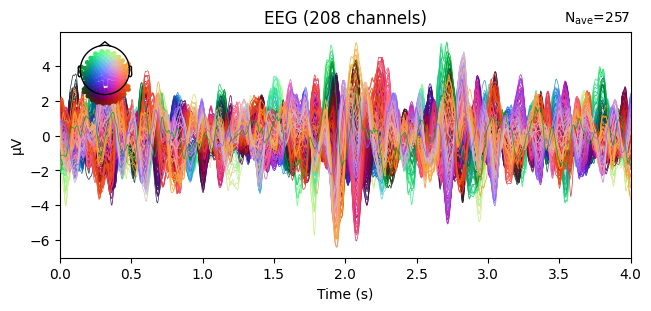

In [13]:
# ----------- Parameters -------------
tmin = 0.0
tmax = 4.0
# ------------------------------------


_ = data["ave"].plot(xlim=(tmin, tmax))

📊 **Check EEG Topographies**

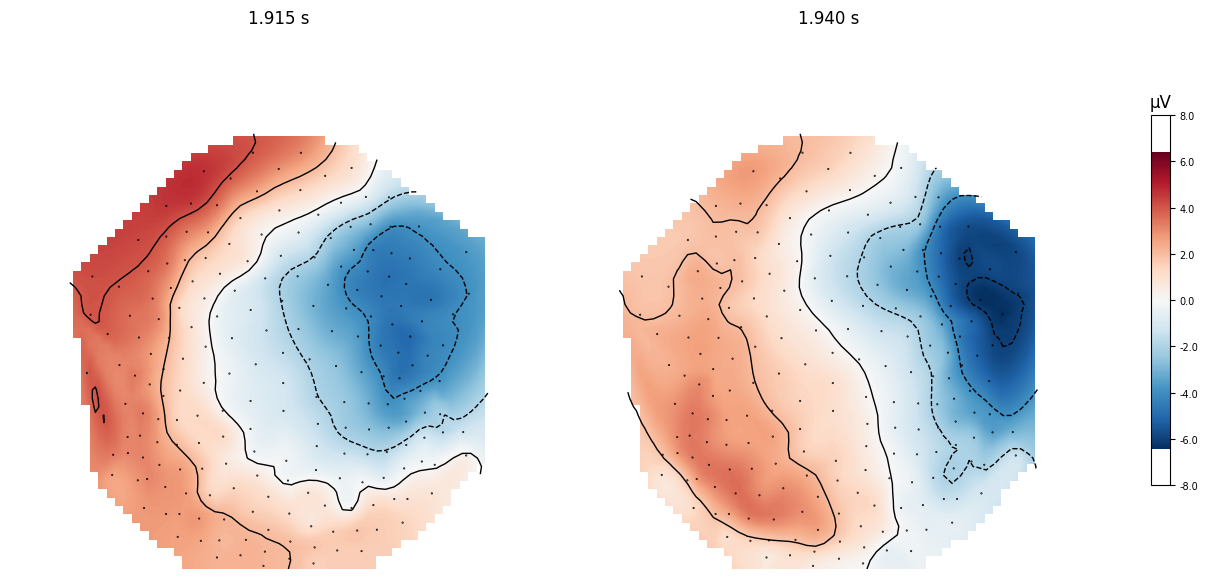

In [14]:
hrp = mm.sensor.get_rising_phase(data["ave"], ratio=0.5)    # half rising phase
pp  = mm.sensor.get_rising_phase(data["ave"], ratio=1)      # peak phase

times = [hrp, pp]
_ = data["ave"].plot_topomap(times=times, size=4, extrapolate="local", outlines=None)

## ⚙️ Apply a source reconstruction method

**Available methods**:

- <font color=gray>MNE</font>: Assumes independent gaussian distributed sources. Uses depth weighting to correct for depth bias.
- <font color=gray>sLORETA</font>: Assumes independent gaussian distributed sources. Applies a post-hoc standardization.
- <font color=gray>dSMP</font>: ...
- <font color=gray>beamformer</font>: ...
- <font color=gray>CSET</font>: Assumes sparse connectome spectrum ($\hat{\mathbf s} = \mathbf U^\intercal \mathbf s \rightarrow$ sparse).
- <font color=gray>wCSET</font>: Assumes independent gaussian distributed connectome spectrum with components weighted by spatial frequency.

🎚️ **<font color=pink>Inverse</font>**:
- `method`: ["MNE", "sLORETA", "dSMP", "beamformer", "CSET", "wCSET"]
- `lam`: Regularizer parameter
- `depth`: Depth weighting exponent
- `relax`: Harmonic weight relaxation

In [15]:
# ------------ Parameters -------------
# method
method = "wcset"

# common parameters
depth = 0
lam   = 1

# wcset parameters
harm = 0.7

# -------------------------------------

if method.lower() == "sloreta":
    ncov = mne.make_ad_hoc_cov(data["ave"].info, std={"eeg":1})

    inverse = mne.minimum_norm.make_inverse_operator(
        info      = data["ave"].info,
        forward   = data["fwd"],
        noise_cov = ncov,
        fixed     = True,
        depth     = depth,               # depth weighting doesn't do anything in sLORETA
        verbose   = "warning",
    )

    stc = mne.minimum_norm.apply_inverse(
        evoked           = data["ave"],
        inverse_operator = inverse,
        lambda2          = lam,
        method           = "sLORETA",
        verbose          = "warning",
    )

elif method.lower() == "cset":
    inverse = mm.inverse.CSET(
        info      = data["ave"].info,
        leadfield = data["fwd"],
        eig_vec   = data["eig"]["vec"],
        noise_cov = None,
        depth     = depth,
    )

    stc = inverse(data["ave"])

elif method.lower() == "wcset":
    # compute wCSET solution
    inverse = mm.inverse.wCSET(
        info            = data["ave"].info,
        leadfield       = data["fwd"],
        noise_cov       = None,
        eig_vec         = data["eig"]["vec"],
        eig_val         = data["eig"]["val"],
        depth           = depth,
        harm            = harm,
    )

    stc = inverse(data["ave"], lam=lam)

else:
    raise ValueError(f"Unknown method '{method}'")

📊 **Source Image**

In [16]:
print(f"halr rising phase: {hrp} [s]")
print(f"peak phase: {pp} [s]")

mm.viz.plot_source_estimate(data["fwd"]["src"], stc, ts_params={"absolute":True}).show()

halr rising phase: 1.915 [s]
peak phase: 1.94 [s]


Widget(value='<iframe src="http://localhost:37361/index.html?ui=P_0x732fc1f965d0_0&reconnect=auto" class="pyvi…

In [17]:
spec = data["eig"]["vec"].T@stc.data
mm.viz.plot_spectrum(spec, stc.times)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 4961 is different from 7465)

In [32]:
# ------------- Parameters ---------------
fconfig = "../../data/config.yml"
subject = "intra-12"
# ----------------------------------------

reader = mm.io.TutoReader(fconfig)
data   = reader(subject, "con", "eig", "src-raw")

eigvec = data["eig"]["vec"]
eigval = data["eig"]["val"]

/home/nino/Code/mindmap/data/derivatives/mindmap/sub-intra-12/src/sub-intra-12_src.fif
DATA SUMMARY
Dataset: tuto
Subject: intra-12
Task: None
Run: None
Retrieved objects:
- eig
- con
- src-raw
Missing objects:


In [4]:
import seaborn as sns

def plot_eigval(eigval, subject="unknown"):
    """
    Plot eigenvalues.
    """
    ax = sns.lineplot(eigval)
    ax.set_title(f"Eigenvalues sub-{subject}")
    ax.set_xlabel("Harmonic index")
    ax.set_ylabel("Eigenvalue")
    

/home/nino/Code/mindmap/data/derivatives/mindmap/sub-intra-12/src/sub-intra-12_src.fif
DATA SUMMARY
Dataset: tuto
Subject: intra-12
Task: None
Run: None
Retrieved objects:
- src-raw
- con
- eig
Missing objects:


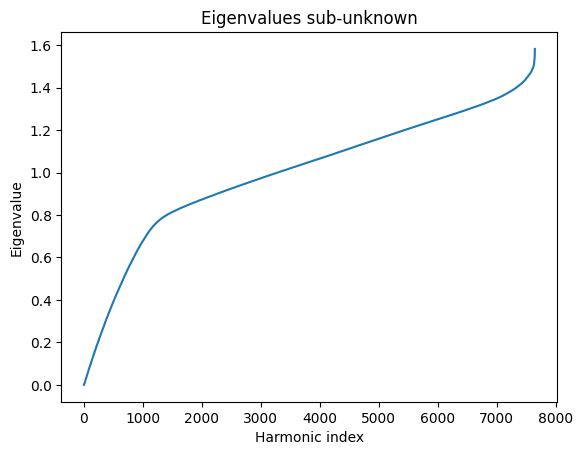

In [5]:
import mindmap as mm

# ------------- Parameters ---------------
fconfig = "../../data/config.yml"
subject = "intra-12"
# ----------------------------------------

reader = mm.io.TutoReader(fconfig)
data   = reader(subject, "con", "eig", "src-raw")

eigvec = data["eig"]["vec"]
eigval = data["eig"]["val"]

plot_eigval(eigval)

In [17]:
pv.set_jupyter_backend("none")
pv.global_theme.jupyter_backend = None

pl = pv.Plotter()
pl.add_mesh(pv.Sphere())
pl.show()